[1/9] Loading data ...
   Could not load the real dataset (HTTPError: 404 Client Error: Not Found for url: https://archive.ics.uci.edu/static/public/4)
   >>> Using a SMALL SYNTHETIC DEMO dataset so the pipeline still runs. <<<
   For real results: download drugsComTrain_raw.tsv from Kaggle/UCI, drag it into the Colab
   Files panel (left sidebar), set OWN_FILE = '/content/drugsComTrain_raw.tsv' and re-run.
Loaded: (4040, 6)

[2/9] EDA on raw data
             missing   pct
condition        121  3.00
usefulCount       83  2.05
drugName           0  0.00
review             0  0.00
rating             0  0.00
date               0  0.00
Duplicate reviews: 1787
Junk condition values (HTML leftovers): 39


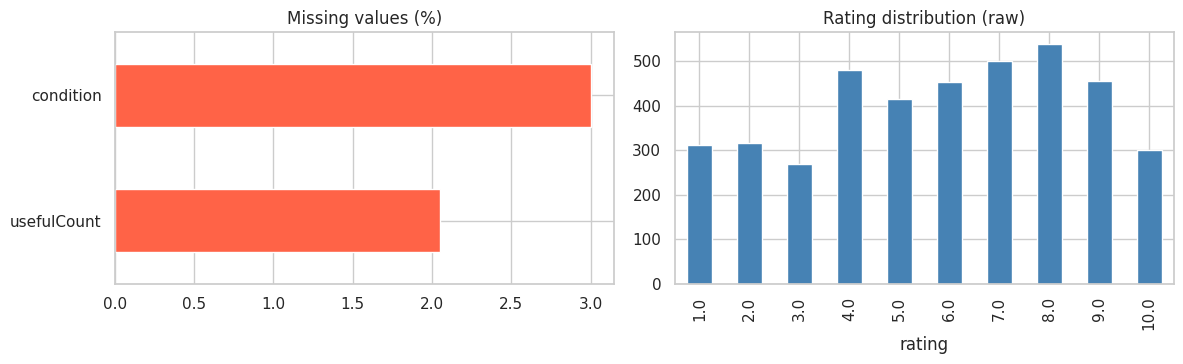


[3/9] Handling missing values + cleaning text
Cleaning: 4,040 -> 2,253 rows | remaining missing: 0

[4/9] Mining side effects
Reviews reporting >=1 side effect: 76.6%
Example -> Worst experience ever, I stopped taking it. I haven't had any rash. The fatigue was awful. 
   reported: ['fatigue/drowsiness'] | negated: ['rash/itching']

[5/9] Labels, features, encoding
Sentiment distribution:
 sentiment
positive    0.396
negative    0.381
neutral     0.223
Name: proportion, dtype: float64

[6/9] EDA on cleaned data


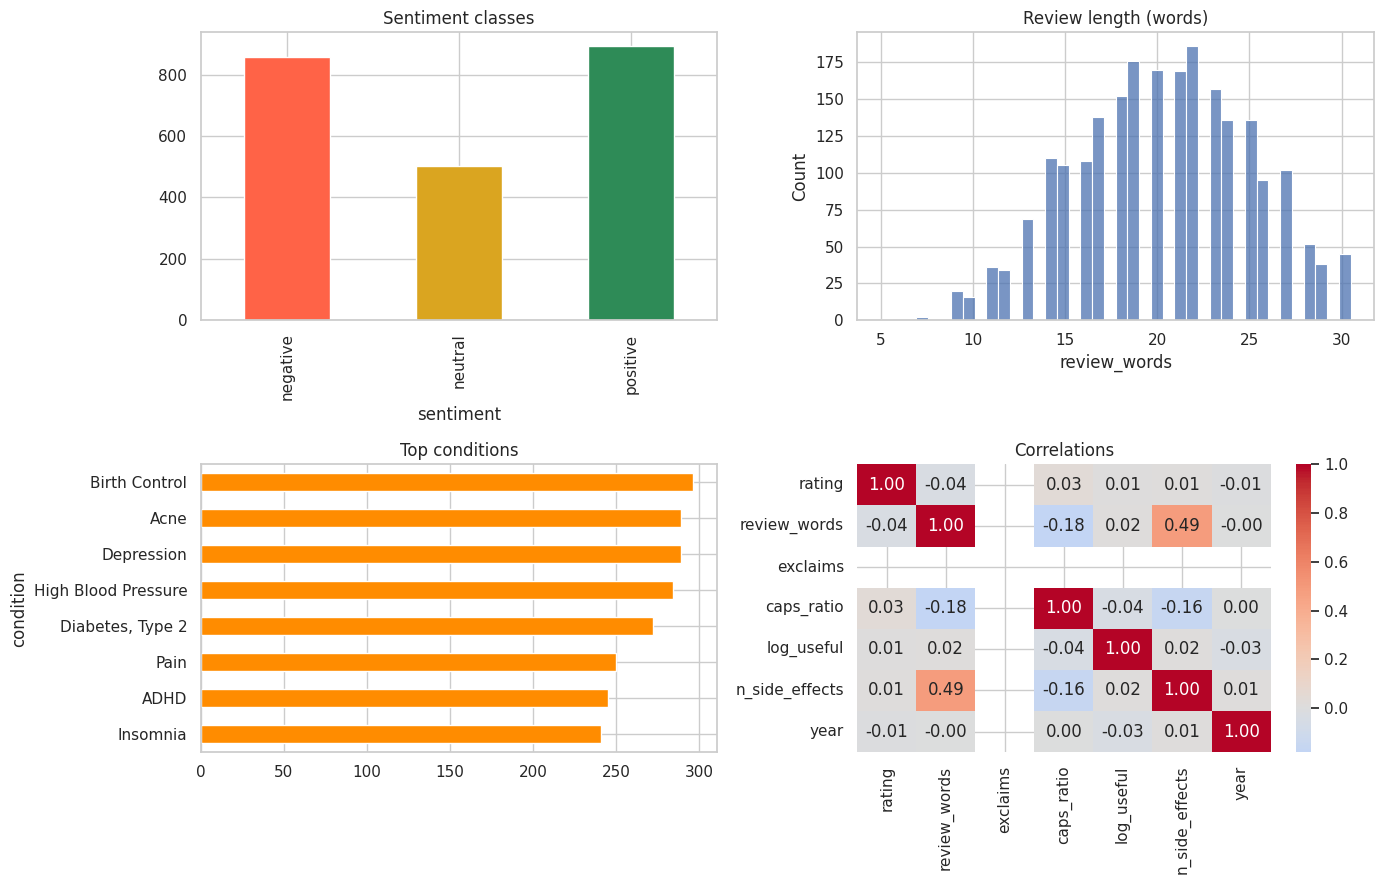


[7/9] Training sentiment models
Feature matrix: train (1802, 334) | test (451, 334)
                      model  accuracy  macro_F1
LinearSVC TF-IDF + features     0.869     0.848
        LogReg  TF-IDF only     0.865     0.843
  LogReg  TF-IDF + features     0.856     0.836

Best model: LinearSVC TF-IDF + features

              precision    recall  f1-score   support

    negative      0.993     0.837     0.909       172
     neutral      0.709     0.730     0.719       100
    positive      0.862     0.978     0.916       179

    accuracy                          0.869       451
   macro avg      0.855     0.848     0.848       451
weighted avg      0.878     0.869     0.870       451



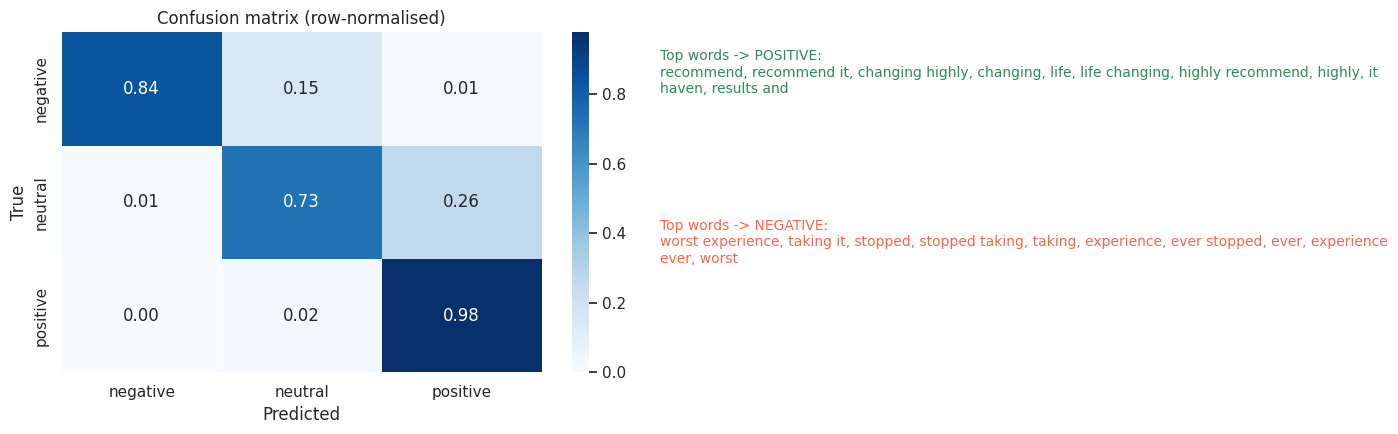

config.json:   0%|          | 0.00/629 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]


Positive-vs-negative on 300 test reviews:
  DistilBERT (pretrained, zero fine-tuning): acc 0.873 | F1 0.855
  LinearSVC TF-IDF + features: acc 0.993 | F1 0.993

[8/9] Side-effect insights
                  n_reviews  mean_rating  pct_positive                                                 top_side_effects
drugName                                                                                                               
Ortho Tri-Cyclen        309          5.5          39.2              constipation (12%), dry mouth (10%), headache (10%)
Accutane                301          5.7          41.5             hair loss (13%), dizziness (12%), constipation (11%)
Lisinopril              301          5.4          37.9        diarrhea (11%), fatigue/drowsiness (10%), dizziness (10%)
Sertraline              295          5.7          41.7     fatigue/drowsiness (12%), constipation (11%), headache (11%)
Metformin               280          5.4          37.5           rash/itching (11%), dizzin

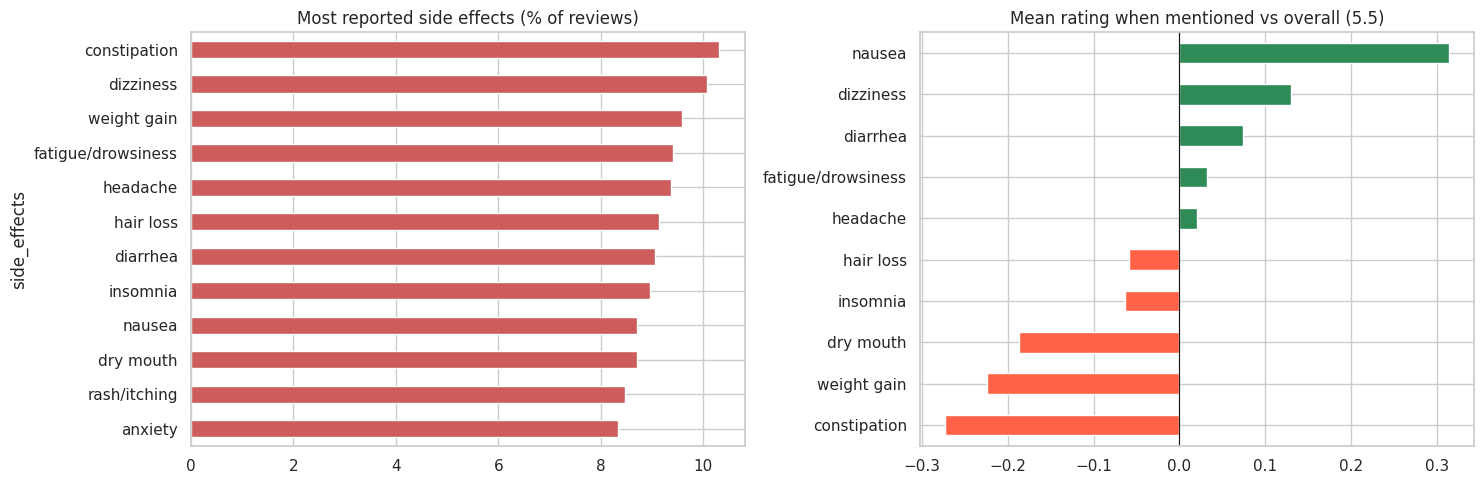

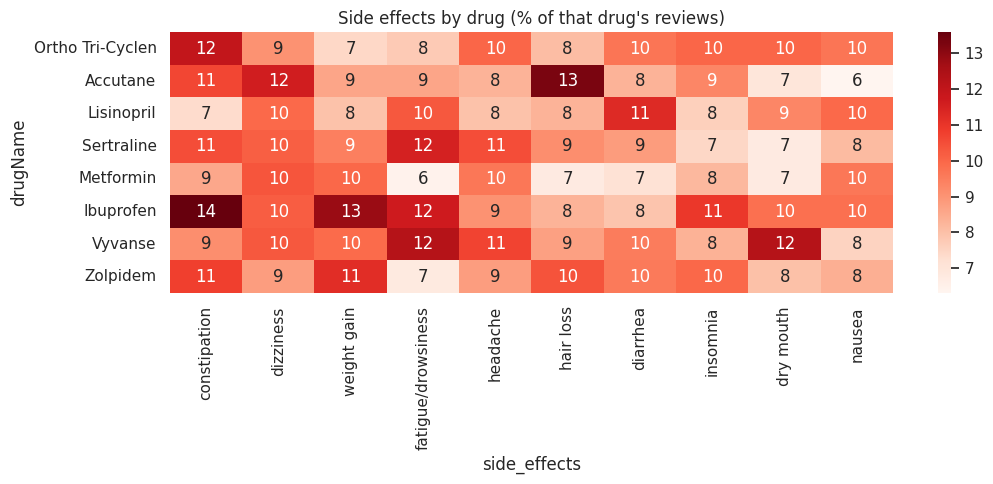

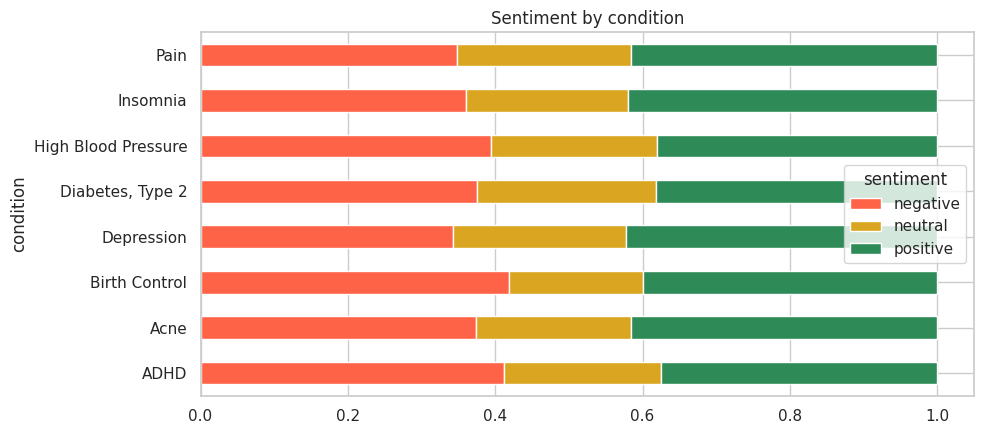


[9/9] Saving + interactive helpers
Saved: drug_reviews_clean.csv, drug_summary.csv (Colab Files panel)

=== Ortho Tri-Cyclen === 309 reviews | mean rating 5.5/10
Sentiment: {'negative': 43, 'positive': 39, 'neutral': 18} (%)
Top reported side effects: {'constipation': '12%', 'dry mouth': '10%', 'headache': '10%', 'insomnia': '10%', 'nausea': '10%', 'diarrhea': '10%', 'anxiety': '10%', 'dizziness': '9%'}


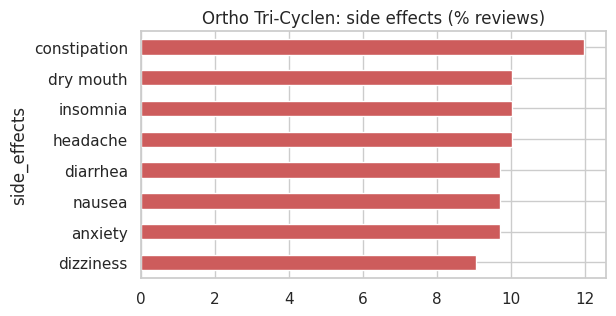


Review: Started this two weeks ago. It helps my mood but I get constant nausea and headaches, no weight gain though.
Sentiment: neutral {'negative': 0.4, 'neutral': 0.45, 'positive': 0.15}
Side effects reported: ['headache', 'nausea'] | mentioned but negated: ['weight gain']

Review: Terrible drug, did not work and I couldn't sleep at all. Stopped after a week.
Sentiment: negative {'negative': 0.95, 'neutral': 0.03, 'positive': 0.02}
Side effects reported: ['insomnia'] | mentioned but negated: none

*** REMINDER: results above are from SYNTHETIC demo data, not the real UCI dataset. ***


In [ ]:
import os, re, io, html, zipfile, warnings
import numpy as np, pandas as pd
import scipy.sparse as sp
import matplotlib.pyplot as plt
import seaborn as sns
import requests
from sklearn.preprocessing import LabelEncoder, StandardScaler, OneHotEncoder
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

# ---------------- SETTINGS ----------------
MAX_ROWS          = 50000   # reviews to use (full data = 215K; more rows = slower)
MIN_DRUG_REVIEWS  = 30      # drugs with fewer reviews are skipped in drug-level tables
USE_TRANSFORMER   = True    # compare against a pretrained DistilBERT (downloads ~260 MB)
TRANSFORMER_N     = 300     # reviews used for that comparison
OWN_FILE          = None    # optional: "/content/drugsComTrain_raw.tsv" (tab or comma separated)
UCI_URL = "https://archive.ics.uci.edu/static/public/462/drug+review+dataset+drugs+com.zip"

# ============ 1. LOAD DATASET ============
print("[1/9] Loading data ...")

def make_demo_data(n=4000, seed=0):
    """Small synthetic stand-in, ONLY used if the real dataset cannot be downloaded."""
    import random
    rng = random.Random(seed)
    drugs = {"Sertraline": "Depression", "Metformin": "Diabetes, Type 2", "Ortho Tri-Cyclen": "Birth Control",
             "Accutane": "Acne", "Lisinopril": "High Blood Pressure", "Zolpidem": "Insomnia",
             "Ibuprofen": "Pain", "Vyvanse": "ADHD"}
    se = ["nausea", "headaches", "dizziness", "weight gain", "insomnia", "dry mouth", "fatigue",
          "hair loss", "rash", "constipation", "anxiety", "diarrhea"]
    pos = ["This medication worked great for me, I feel so much better.", "Life changing, highly recommend it.",
           "Very happy with the results and it works fast."]
    neg = ["This drug was terrible and did not help at all.", "Worst experience ever, I stopped taking it.",
           "I regret starting this medicine, it made things worse."]
    neu = ["It helped a little but nothing dramatic.", "Mixed feelings, some days are good and some are bad."]
    rows = []
    for i in range(n):
        d = rng.choice(list(drugs)); k = rng.random()
        if k < .5: txt, r = rng.choice(pos), rng.randint(7, 10)
        elif k < .8: txt, r = rng.choice(neg), rng.randint(1, 4)
        else: txt, r = rng.choice(neu), rng.randint(5, 6)
        for _ in range(rng.randint(0, 3)):
            s = rng.choice(se)
            txt += rng.choice([f" I had {s} for the first weeks.", f" No {s} at all.", f" The {s} was awful.",
                               f" I haven&#039;t had any {s}."])
            if r > 4 and rng.random() < .3: r -= 1
        cond = drugs[d]
        if rng.random() < .03: cond = None
        elif rng.random() < .01: cond = "3</span> users found this comment helpful."
        rows.append({"drugName": d, "condition": cond, "review": '"' + txt + '"', "rating": float(r),
                     "date": f"{rng.choice(['January','May','October'])} {rng.randint(1,28)}, {rng.randint(2009,2017)}",
                     "usefulCount": rng.randint(0, 80) if rng.random() > .02 else None})
    rows += rows[:40]   # duplicates
    return pd.DataFrame(rows)

df, USING_DEMO = None, False
try:
    if OWN_FILE:
        df = pd.read_csv(OWN_FILE, sep=None, engine="python")
    else:
        resp = requests.get(UCI_URL, timeout=180); resp.raise_for_status()
        z = zipfile.ZipFile(io.BytesIO(resp.content))
        parts = [pd.read_csv(z.open(n), sep="\t") for n in z.namelist() if n.lower().endswith((".tsv", ".csv"))]
        df = pd.concat(parts, ignore_index=True)
except Exception as ex:
    print(f"   Could not load the real dataset ({type(ex).__name__}: {str(ex)[:80]})")
    print("   >>> Using a SMALL SYNTHETIC DEMO dataset so the pipeline still runs. <<<")
    print("   For real results: download drugsComTrain_raw.tsv from Kaggle/UCI, drag it into the Colab")
    print("   Files panel (left sidebar), set OWN_FILE = '/content/drugsComTrain_raw.tsv' and re-run.")
    df, USING_DEMO = make_demo_data(), True

std = {"drugname": "drugName", "condition": "condition", "review": "review", "rating": "rating",
       "date": "date", "usefulcount": "usefulCount"}
df = df.rename(columns={c: std[c.lower().strip()] for c in df.columns if c.lower().strip() in std})
df = df[[c for c in std.values() if c in df.columns]]
assert {"review", "rating"} <= set(df.columns), f"Need review + rating columns. Found {list(df.columns)}"
for c in ["drugName", "condition", "date", "usefulCount"]:
    if c not in df: df[c] = np.nan
if len(df) > MAX_ROWS:
    df = df.sample(MAX_ROWS, random_state=42).reset_index(drop=True)
print("Loaded:", df.shape)

# ============ 2. EDA (RAW) ============
print("\n[2/9] EDA on raw data")
miss = pd.DataFrame({"missing": df.isna().sum(), "pct": (df.isna().mean() * 100).round(2)})
print(miss.sort_values("pct", ascending=False))
print("Duplicate reviews:", df.duplicated(subset="review").sum())
junk_mask = df["condition"].astype(str).str.contains("</span>|users found this comment", case=False, na=False)
print("Junk condition values (HTML leftovers):", int(junk_mask.sum()))
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
miss[miss.pct > 0]["pct"].sort_values().plot.barh(ax=ax[0], color="tomato"); ax[0].set_title("Missing values (%)")
pd.to_numeric(df["rating"], errors="coerce").value_counts().sort_index().plot(kind="bar", ax=ax[1], color="steelblue")
ax[1].set_title("Rating distribution (raw)")
plt.tight_layout(); plt.show()

# ============ 3. HANDLE MISSING VALUES + CLEAN TEXT ============
print("\n[3/9] Handling missing values + cleaning text")
n0 = len(df)

def clean_review(s):
    s = html.unescape(str(s))                       # &#039; -> '
    s = s.replace("\u2019", "'").replace("\r", " ").replace("\n", " ")
    s = re.sub(r"http\S+|www\.\S+", " ", s)         # urls
    s = s.strip().strip('"').strip("'")
    return re.sub(r"\s+", " ", s).strip()

df.loc[junk_mask, "condition"] = np.nan                         # junk condition -> missing
df["rating"] = pd.to_numeric(df["rating"], errors="coerce")
df = df.dropna(subset=["review", "rating"])                     # essential fields
df = df[df["rating"].between(1, 10)]
df["review"] = df["review"].apply(clean_review)
df = df.drop_duplicates(subset="review")                        # duplicates
df = df[df["review"].str.split().str.len() >= 5]                # too-short junk

df["condition"] = df["condition"].fillna("Unknown").astype(str).str.strip().replace("", "Unknown")
df["drugName"] = df["drugName"].fillna("Unknown").astype(str).str.strip()
df["usefulCount"] = pd.to_numeric(df["usefulCount"], errors="coerce")
df["usefulCount"] = df["usefulCount"].fillna(df["usefulCount"].median() if df["usefulCount"].notna().any() else 0)
dates = pd.to_datetime(df["date"], errors="coerce")                              # median date imputation
df["year"] = dates.dt.year.fillna(dates.dt.year.median() if dates.notna().any() else 0).astype(int)
df["review_lc"] = df["review"].str.lower()
df = df.reset_index(drop=True)
print(f"Cleaning: {n0:,} -> {len(df):,} rows | remaining missing: {int(df.isna().sum().sum())}")

# ============ 4. SIDE-EFFECT MINING (lexicon NER + negation) ============
print("\n[4/9] Mining side effects")
LEXICON = {
    "nausea": ["nausea", "nauseous", "nauseated", "queasy"],
    "vomiting": ["vomiting", "vomit", "threw up", "throwing up"],
    "headache": ["headache", "headaches", "migraine", "migraines"],
    "dizziness": ["dizzy", "dizziness", "lightheaded", "light headed", "vertigo"],
    "fatigue/drowsiness": ["fatigue", "tired", "exhausted", "exhaustion", "lethargic", "drowsy", "drowsiness", "sleepy"],
    "insomnia": ["insomnia", "can't sleep", "cannot sleep", "couldn't sleep", "trouble sleeping", "sleeplessness"],
    "weight gain": ["weight gain", "gained weight", "gain weight", "gaining weight", "put on weight"],
    "weight loss": ["weight loss", "lost weight", "losing weight"],
    "increased appetite": ["increased appetite", "always hungry", "constant hunger"],
    "loss of appetite": ["loss of appetite", "no appetite", "lost my appetite", "decreased appetite"],
    "anxiety": ["anxiety", "anxious", "panic attack", "panic attacks"],
    "mood swings": ["mood swings", "mood swing", "irritable", "irritability", "angry outbursts"],
    "depression/low mood": ["depressed", "suicidal thoughts", "crying spells"],
    "acne/breakouts": ["acne", "breakouts", "breakout", "pimples"],
    "rash/itching": ["rash", "rashes", "hives", "itching", "itchy"],
    "diarrhea": ["diarrhea", "diarrhoea", "loose stools"],
    "constipation": ["constipation", "constipated"],
    "stomach pain/cramps": ["stomach pain", "stomach ache", "stomach cramps", "cramps", "cramping", "abdominal pain"],
    "bloating/gas": ["bloating", "bloated", "gas"],
    "dry mouth": ["dry mouth", "cotton mouth"],
    "hair loss": ["hair loss", "hair falling out", "losing hair", "thinning hair"],
    "sweating": ["sweating", "night sweats", "sweats"],
    "tremor/shaking": ["tremor", "tremors", "shaking", "jittery", "jitters"],
    "blurred vision": ["blurred vision", "blurry vision"],
    "heart palpitations": ["palpitations", "heart racing", "racing heart", "rapid heartbeat"],
    "muscle/joint pain": ["muscle pain", "muscle aches", "joint pain", "body aches", "achy"],
    "low libido/sexual problems": ["low libido", "no sex drive", "loss of libido", "erectile", "sexual side effects"],
    "brain fog/memory": ["brain fog", "memory loss", "memory problems", "foggy", "confusion"],
    "numbness/tingling": ["numbness", "tingling", "numb"],
    "swelling": ["swelling", "swollen", "edema"],
    "spotting/irregular periods": ["spotting", "irregular periods", "breakthrough bleeding"],
    "dry skin": ["dry skin", "dry lips", "chapped lips"],
    "cough": ["cough", "coughing"],
}
PHRASE2CANON = {p: c for c, ps in LEXICON.items() for p in ps}
SE_PATTERN = re.compile(r"\b(?:" + "|".join(re.escape(p) for p in sorted(PHRASE2CANON, key=len, reverse=True)) + r")\b")
NEG = {"no", "not", "never", "without", "didn't", "didnt", "don't", "dont", "haven't", "havent", "hasn't",
       "hasnt", "wasn't", "wasnt", "free", "zero", "nothing", "none", "neither", "nor", "isn't", "isnt", "aren't"}
CLAUSE_SPLIT = re.compile(r"[.;!?]|\bbut\b|\bhowever\b|\balthough\b")

def extract_side_effects(text):
    """Returns (reported_side_effects, negated_mentions). 'no nausea' counts as negated, not reported."""
    reported, negated = set(), set()
    for clause in CLAUSE_SPLIT.split(text):
        for m in SE_PATTERN.finditer(clause):
            before = re.findall(r"[a-z']+", clause[:m.start()].split(",")[-1])[-3:]   # 3-word window, stops at commas
            (negated if any(w in NEG for w in before) else reported).add(PHRASE2CANON[m.group(0)])
    return sorted(reported), sorted(negated)

res = df["review_lc"].apply(extract_side_effects)
df["side_effects"] = res.str[0]
df["negated_mentions"] = res.str[1]
df["n_side_effects"] = df["side_effects"].str.len()
print(f"Reviews reporting >=1 side effect: {(df.n_side_effects > 0).mean()*100:.1f}%")
ex = df[(df.n_side_effects > 0) & (df.negated_mentions.str.len() > 0)].head(1)
for _, r in ex.iterrows():
    print("Example ->", r.review[:160], "\n   reported:", r.side_effects, "| negated:", r.negated_mentions)

# ============ 5. LABELS + FEATURE ENGINEERING + ENCODING ============
print("\n[5/9] Labels, features, encoding")
df["sentiment"] = pd.cut(df["rating"], bins=[0, 4, 6, 10], labels=["negative", "neutral", "positive"]).astype(str)
le = LabelEncoder()
df["target"] = le.fit_transform(df["sentiment"])
print("Sentiment distribution:\n", df["sentiment"].value_counts(normalize=True).round(3))

df["review_words"] = df["review"].str.split().str.len()
df["review_chars"] = df["review"].str.len()
df["avg_word_len"] = df["review_chars"] / df["review_words"].clip(lower=1)
df["exclaims"] = df["review"].str.count("!")
df["questions"] = df["review"].str.count(r"\?")
df["caps_ratio"] = df["review"].apply(lambda s: sum(c.isupper() for c in s) / max(len(s), 1))
df["log_useful"] = np.log1p(df["usefulCount"])
top_cond = df["condition"].value_counts().head(20).index
top_drug = df["drugName"].value_counts().head(20).index
df["condition_grp"] = np.where(df["condition"].isin(top_cond), df["condition"], "Other")      # rare -> Other
df["drug_grp"] = np.where(df["drugName"].isin(top_drug), df["drugName"], "Other")

# ============ 6. EDA (CLEAN) ============
print("\n[6/9] EDA on cleaned data")
fig, ax = plt.subplots(2, 2, figsize=(14, 9))
df["sentiment"].value_counts().reindex(["negative", "neutral", "positive"]).plot(
    kind="bar", ax=ax[0, 0], color=["tomato", "goldenrod", "seagreen"]); ax[0, 0].set_title("Sentiment classes")
sns.histplot(df["review_words"].clip(upper=df["review_words"].quantile(.99)), bins=40, ax=ax[0, 1])
ax[0, 1].set_title("Review length (words)")
df["condition"].value_counts().drop("Unknown", errors="ignore").head(12).sort_values().plot.barh(ax=ax[1, 0], color="darkorange")
ax[1, 0].set_title("Top conditions")
sns.heatmap(df[["rating", "review_words", "exclaims", "caps_ratio", "log_useful", "n_side_effects", "year"]].corr(),
            annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax[1, 1]); ax[1, 1].set_title("Correlations")
plt.tight_layout(); plt.show()

# ============ 7. SENTIMENT MODELS ============
print("\n[7/9] Training sentiment models")
strat = df["target"] if df["target"].value_counts().min() >= 2 else None
idx_tr, idx_te = train_test_split(df.index, test_size=0.2, random_state=42, stratify=strat)
tr, te = df.loc[idx_tr], df.loc[idx_te]

# Keep negations ("not", "no") -> NO stop-word removal for sentiment
tfidf = TfidfVectorizer(max_features=50000, ngram_range=(1, 2), min_df=3, sublinear_tf=True)
Xt_tr, Xt_te = tfidf.fit_transform(tr["review"]), tfidf.transform(te["review"])
num_cols = ["review_words", "avg_word_len", "exclaims", "questions", "caps_ratio", "log_useful", "n_side_effects", "year"]
scaler = StandardScaler()
Xn_tr, Xn_te = scaler.fit_transform(tr[num_cols]), scaler.transform(te[num_cols])
ohe = OneHotEncoder(handle_unknown="ignore")
Xc_tr, Xc_te = ohe.fit_transform(tr[["condition_grp", "drug_grp"]]), ohe.transform(te[["condition_grp", "drug_grp"]])
X_tr = sp.hstack([Xt_tr, sp.csr_matrix(Xn_tr), Xc_tr]).tocsr()
X_te = sp.hstack([Xt_te, sp.csr_matrix(Xn_te), Xc_te]).tocsr()
y_tr, y_te = tr["target"].values, te["target"].values
print(f"Feature matrix: train {X_tr.shape} | test {X_te.shape}")

models = {
    "LogReg  TF-IDF only":        (LogisticRegression(max_iter=1000, class_weight="balanced"), Xt_tr, Xt_te),
    "LogReg  TF-IDF + features":  (LogisticRegression(max_iter=1000, class_weight="balanced"), X_tr, X_te),
    "LinearSVC TF-IDF + features": (LinearSVC(class_weight="balanced"), X_tr, X_te),
}
results, fitted = [], {}
for name, (m, A, B) in models.items():
    m.fit(A, y_tr); p = m.predict(B); fitted[name] = (m, B, p)
    results.append({"model": name, "accuracy": accuracy_score(y_te, p), "macro_F1": f1_score(y_te, p, average="macro")})
res_df = pd.DataFrame(results).sort_values("macro_F1", ascending=False).round(3)
print(res_df.to_string(index=False))
best_name = res_df.iloc[0]["model"]
best_model, best_B, best_pred = fitted[best_name]
print(f"\nBest model: {best_name}\n")
print(classification_report(y_te, best_pred, target_names=le.classes_, digits=3))

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
cm = confusion_matrix(y_te, best_pred, normalize="true")
sns.heatmap(cm, annot=True, fmt=".2f", cmap="Blues", xticklabels=le.classes_, yticklabels=le.classes_, ax=ax[0])
ax[0].set_title("Confusion matrix (row-normalised)"); ax[0].set_xlabel("Predicted"); ax[0].set_ylabel("True")
lr_text = fitted["LogReg  TF-IDF only"][0]                         # explainability: strongest words
vocab = np.array(tfidf.get_feature_names_out())
pos_i, neg_i = list(le.classes_).index("positive"), list(le.classes_).index("negative")
coef = lr_text.coef_
top_pos, top_neg = vocab[np.argsort(-coef[pos_i])[:10]], vocab[np.argsort(-coef[neg_i])[:10]]
ax[1].axis("off")
ax[1].text(0, .95, "Top words -> POSITIVE:\n" + ", ".join(top_pos), fontsize=10, va="top", wrap=True, color="seagreen")
ax[1].text(0, .45, "Top words -> NEGATIVE:\n" + ", ".join(top_neg), fontsize=10, va="top", wrap=True, color="tomato")
plt.tight_layout(); plt.show()

# ---- Optional: pretrained transformer (no training) vs our model, positive-vs-negative reviews only
if USE_TRANSFORMER:
    try:
        from transformers import pipeline
        import torch
        pipe = pipeline("sentiment-analysis", model="distilbert-base-uncased-finetuned-sst-2-english",
                        device=0 if torch.cuda.is_available() else -1)
        te_r = te.reset_index(drop=True)
        pn = np.where(te_r["sentiment"].isin(["negative", "positive"]))[0]
        pn = np.random.RandomState(0).choice(pn, size=min(TRANSFORMER_N, len(pn)), replace=False)
        outs = pipe(te_r.loc[pn, "review"].tolist(), batch_size=16, truncation=True, max_length=256)
        tf_pred = np.array([1 if o["label"] == "POSITIVE" else 0 for o in outs])
        truth = (te_r.loc[pn, "sentiment"] == "positive").astype(int).values
        scores = best_model.decision_function(best_B)[pn][:, [neg_i, pos_i]]      # our model, neg vs pos only
        our_pred = scores.argmax(axis=1)
        print(f"\nPositive-vs-negative on {len(pn)} test reviews:")
        print(f"  DistilBERT (pretrained, zero fine-tuning): acc {accuracy_score(truth, tf_pred):.3f} | F1 {f1_score(truth, tf_pred):.3f}")
        print(f"  {best_name}: acc {accuracy_score(truth, our_pred):.3f} | F1 {f1_score(truth, our_pred):.3f}")
    except Exception as ex:
        print("\nTransformer comparison skipped:", type(ex).__name__, str(ex)[:100])

# ============ 8. SIDE-EFFECT INSIGHTS ============
print("\n[8/9] Side-effect insights")
exp = (df[["drugName", "rating", "sentiment", "side_effects"]].explode("side_effects")
       .dropna(subset=["side_effects"]).reset_index(drop=True))
se_pct = (exp["side_effects"].value_counts() / len(df) * 100).head(15)

drug_counts = df.groupby("drugName").size()
eligible = drug_counts[(drug_counts >= MIN_DRUG_REVIEWS) & (drug_counts.index != "Unknown")].index
if len(eligible) < 3:
    eligible = drug_counts[drug_counts.index != "Unknown"].nlargest(10).index
ct = pd.crosstab(exp["drugName"], exp["side_effects"]).reindex(eligible).fillna(0)
ct_pct = ct.div(drug_counts.reindex(eligible), axis=0) * 100

summary = df[df["drugName"].isin(eligible)].groupby("drugName").agg(
    n_reviews=("rating", "size"), mean_rating=("rating", "mean"),
    pct_positive=("sentiment", lambda s: (s == "positive").mean() * 100)).round(1)
summary["top_side_effects"] = [", ".join(f"{c} ({ct_pct.loc[d, c]:.0f}%)" for c in ct_pct.loc[d].nlargest(3).index
                                         if ct_pct.loc[d, c] > 0) for d in summary.index]
summary = summary.sort_values("n_reviews", ascending=False)
print(summary.head(10).to_string())

fig, ax = plt.subplots(1, 2, figsize=(15, 5))
se_pct.sort_values().plot.barh(ax=ax[0], color="indianred"); ax[0].set_title("Most reported side effects (% of reviews)")
base = df["rating"].mean()
eff = pd.Series({s: exp.loc[exp.side_effects == s, "rating"].mean() - base
                 for s in se_pct.index[:10]}).sort_values()
eff.plot.barh(ax=ax[1], color=["tomato" if v < 0 else "seagreen" for v in eff]); ax[1].axvline(0, color="k", lw=.8)
ax[1].set_title(f"Mean rating when mentioned vs overall ({base:.1f})")
plt.tight_layout(); plt.show()

top_d = drug_counts.reindex(eligible).nlargest(10).index
top_s = se_pct.index[:10]
heat = ct_pct.reindex(index=top_d, columns=top_s).fillna(0)
plt.figure(figsize=(11, 5)); sns.heatmap(heat, annot=True, fmt=".0f", cmap="Reds")
plt.title("Side effects by drug (% of that drug's reviews)"); plt.tight_layout(); plt.show()

cond_ok = df["condition"].value_counts().drop("Unknown", errors="ignore").head(10).index
cs = pd.crosstab(df[df.condition.isin(cond_ok)]["condition"], df["sentiment"], normalize="index")
cs.reindex(columns=["negative", "neutral", "positive"]).plot(
    kind="barh", stacked=True, color=["tomato", "goldenrod", "seagreen"], figsize=(10, 4.5))
plt.title("Sentiment by condition"); plt.tight_layout(); plt.show()

# ============ 9. TOOLS YOU CAN USE ============
print("\n[9/9] Saving + interactive helpers")
df.drop(columns=["review_lc"]).to_csv("drug_reviews_clean.csv", index=False)
summary.to_csv("drug_summary.csv")
print("Saved: drug_reviews_clean.csv, drug_summary.csv (Colab Files panel)")

def drug_report(name):
    """Per-drug report: rating, sentiment split, most reported side effects."""
    hit = df[df["drugName"].str.lower() == name.lower()]
    if hit.empty:
        hit = df[df["drugName"].str.lower().str.contains(name.lower(), regex=False)]
    if hit.empty: return print(f"No reviews found for '{name}'. Try one of: {list(drug_counts.nlargest(8).index)}")
    n = len(hit); e = hit["side_effects"].explode().dropna().value_counts().head(8)
    print(f"\n=== {hit['drugName'].mode()[0]} === {n} reviews | mean rating {hit['rating'].mean():.1f}/10")
    print("Sentiment:", (hit["sentiment"].value_counts(normalize=True) * 100).round(0).astype(int).to_dict(), "(%)")
    print("Top reported side effects:", {k: f"{v / n * 100:.0f}%" for k, v in e.items()} or "none found")
    if len(e): (e / n * 100).sort_values().plot.barh(color="indianred", figsize=(6, 3.2), title=f"{name}: side effects (% reviews)"); plt.show()

def analyze_review(text):
    """Sentiment + side effects for any new review text."""
    clean = clean_review(text)
    proba = lr_text.predict_proba(tfidf.transform([clean]))[0]
    rep, neg = extract_side_effects(clean.lower())
    print(f"\nReview: {clean[:200]}")
    print("Sentiment:", le.classes_[proba.argmax()], {c: round(float(p), 2) for c, p in zip(le.classes_, proba)})
    print("Side effects reported:", rep or "none", "| mentioned but negated:", neg or "none")

drug_report(drug_counts.drop("Unknown", errors="ignore").idxmax())
analyze_review("Started this two weeks ago. It helps my mood but I get constant nausea and headaches, no weight gain though.")
analyze_review("Terrible drug, did not work and I couldn't sleep at all. Stopped after a week.")
# drug_report("Sertraline")      # <- try your own drug name
# analyze_review("your own review text here")
if USING_DEMO: print("\n*** REMINDER: results above are from SYNTHETIC demo data, not the real UCI dataset. ***")